# Лабораторная работа №4: Self-supervised learning визуальных представлений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Извлечь frozen DINO embeddings.
- Сравнить k-NN и linear probe при 1/10/100% меток.
- Исследовать ближайших соседей и shortcut features.


## Теоретическая часть

Self-supervised encoder обучается без классов: contrastive objective сближает представления двух views одного изображения, masked modeling восстанавливает скрытые токены. Качество representation проверяют frozen k-NN и linear probe.

![DINO](https://raw.githubusercontent.com/facebookresearch/dino/main/.github/dino.gif)


### Математическая постановка

InfoNCE для пары $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.$$
Linear probe обучает только $W$ в $\hat y=\arg\max Wz$.


### Материалы

- [DINOv2](https://github.com/facebookresearch/dinov2)
- [SimCLR](https://arxiv.org/abs/2002.05709)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Извлечь frozen DINO embeddings.
2. Сравнить k-NN и linear probe при 1/10/100% меток.
3. Исследовать ближайших соседей и shortcut features.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** DINOv2 ViT-S/14 frozen, FP16.
- **Ограничение данных:** до 5 000 изображений.
- **Fallback:** ResNet18 frozen embeddings.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 19
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
DATA_ROOT = Path.cwd() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': 'c:\\Anton\\16 триместр\\SOTA\\lab4\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

In [3]:
# Библиотеки
import torch
from torch.utils.data import DataLoader, Subset, Dataset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

import torch.nn.functional as F

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

from torch import nn
import joblib

from sklearn.neighbors import NearestNeighbors

### Стратифицированные разбиения CIFAR-10

*Вес: 1 балл.*

**Постановка.** Train, validation и test изолируют подбор параметров линейного probe.

Выполните следующие действия:
1. Загрузите CIFAR-10 и стратифицируйте train.
2. Подготовьте неизменяемые индексы test.

**Результат.** Датасет ds, загрузчик loader и длины трёх выборок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
SPLITS_PATH = ARTIFACTS / "cifar10_splits.json"
BATCH_SIZE = 16 if FAST_DEV_RUN else 128

transform = transforms.ToTensor()

ds = datasets.CIFAR10(
    root=str(DATA_ROOT),
    train=True,
    download=True,
    transform=transform
)

test_ds = datasets.CIFAR10(
    root=str(DATA_ROOT),
    train=False,
    download=True,
    transform=transform
)

train_labels = np.asarray(ds.targets)
test_labels = np.asarray(test_ds.targets)

if FAST_DEV_RUN:
    n_train, n_val, n_test = 200, 40, 100
else:
    n_train, n_val, n_test = 10000, 2000, 5000

# Загружаем сохранённые индексы или создаём новые
if SPLITS_PATH.exists():
    with open(SPLITS_PATH, "r", encoding="utf-8") as f:
        saved = json.load(f)

    # Пересоздаём разбиения, если конфигурация отличается
    if (
        saved.get("seed") != SEED
        or saved.get("n_train") != n_train
        or saved.get("n_val") != n_val
        or saved.get("n_test") != n_test
    ):
        saved = None
else:
    saved = None

if saved is None:
    # Отбираем train + validation из исходного train CIFAR-10
    train_val_idx, _ = train_test_split(
        np.arange(len(ds)),
        train_size=n_train + n_val,
        random_state=SEED,
        stratify=train_labels
    )

    train_idx, val_idx = train_test_split(
        train_val_idx,
        train_size=n_train,
        random_state=SEED,
        stratify=train_labels[train_val_idx]
    )

    # Отдельная стратифицированная подвыборка исходного test
    test_idx, _ = train_test_split(
        np.arange(len(test_ds)),
        train_size=n_test,
        random_state=SEED,
        stratify=test_labels
    )

    saved = {
        "seed": SEED,
        "n_train": n_train,
        "n_val": n_val,
        "n_test": n_test,
        "train": train_idx.tolist(),
        "val": val_idx.tolist(),
        "test": test_idx.tolist()
    }

    with open(SPLITS_PATH, "w", encoding="utf-8") as f:
        json.dump(saved, f)

train_idx = np.asarray(saved["train"], dtype=np.int64)
val_idx = np.asarray(saved["val"], dtype=np.int64)
test_idx = np.asarray(saved["test"], dtype=np.int64)

train_set = Subset(ds, train_idx.tolist())
val_set = Subset(ds, val_idx.tolist())
test_set = Subset(test_ds, test_idx.tolist())

loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print(f"Train: {len(train_set)}")
print(f"Validation: {len(val_set)}")
print(f"Test: {len(test_set)}")
print(f"Разбиения сохранены: {SPLITS_PATH}")


Train: 10000
Validation: 2000
Test: 5000
Разбиения сохранены: artifacts\cifar10_splits.json


### Предобученный DINOv2 и признаки

*Вес: 1 балл.*

**Постановка.** Frozen encoder предоставляет представления без доступа к меткам при извлечении.

Выполните следующие действия:
1. Загрузите DINOv2 ViT-S/14.
2. Сохраните нормированные признаки и явные train/validation/test индексы.

**Результат.** embeddings.npz с фактическими DINO-признаками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
# Конфигурация
EMBEDDINGS_PATH = ARTIFACTS / "embeddings.npz"
EXTRACT_BATCH_SIZE = 4 if FAST_DEV_RUN else 8

# Загружаем предобученный DINOv2 ViT-S/14
model = torch.hub.load(
    "facebookresearch/dinov2",
    "dinov2_vits14"
)
model = model.to(DEVICE)
model.eval()

# Индексы должны быть определены предыдущей ячейкой
train_idx = np.asarray(train_idx, dtype=np.int64)
val_idx = np.asarray(val_idx, dtype=np.int64)
test_idx = np.asarray(test_idx, dtype=np.int64)

# Для извлечения используем фиксированный порядок изображений
train_extract_loader = DataLoader(
    Subset(ds, train_idx.tolist()),
    batch_size=EXTRACT_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

val_extract_loader = DataLoader(
    Subset(ds, val_idx.tolist()),
    batch_size=EXTRACT_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_extract_loader = DataLoader(
    Subset(test_ds, test_idx.tolist()),
    batch_size=EXTRACT_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Подготовка CIFAR-10 для DINOv2:
# увеличение разрешения, центральное кадрирование,
# нормализация по статистикам ImageNet
mean = torch.tensor(
    [0.485, 0.456, 0.406], device=DEVICE
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225], device=DEVICE
).view(1, 3, 1, 1)


def extract_embeddings(data_loader):
    features = []

    with torch.inference_mode():
        for images, _ in data_loader:
            images = images.to(DEVICE)

            images = F.interpolate(
                images,
                size=(256, 256),
                mode="bicubic",
                align_corners=False,
                antialias=True
            )

            images = images[:, :, 16:240, 16:240]
            images = (images - mean) / std

            # Только прямой проход замороженного encoder
            embeddings = model(images)

            # L2-нормализация каждого вектора
            embeddings = F.normalize(
                embeddings.float(),
                p=2,
                dim=1
            )

            features.append(embeddings.cpu().numpy())

    return np.concatenate(features, axis=0).astype(np.float32)


# Извлекаем признаки независимо для каждой выборки
X_train = extract_embeddings(train_extract_loader)
X_val = extract_embeddings(val_extract_loader)
X_test = extract_embeddings(test_extract_loader)

# Метки сохраняются отдельно от признаков
y_train = np.asarray(ds.targets)[train_idx]
y_val = np.asarray(ds.targets)[val_idx]
y_test = np.asarray(test_ds.targets)[test_idx]

# Сохраняем признаки, метки и точные индексы
np.savez_compressed(
    EMBEDDINGS_PATH,
    X_train=X_train,
    X_val=X_val,
    X_test=X_test,
    y_train=y_train,
    y_val=y_val,
    y_test=y_test,
    train_indices=train_idx,
    val_indices=val_idx,
    test_indices=test_idx
)

print("Embeddings сохранены:", EMBEDDINGS_PATH)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Размерность признаков:", X_train.shape[1])


Using cache found in C:\Users\anton/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\anton/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\anton/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\anton/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Embeddings сохранены: artifacts\embeddings.npz
Train: (10000, 384)
Validation: (2000, 384)
Test: (5000, 384)
Размерность признаков: 384


### Подбор k-NN на validation

*Вес: 1 балл.*

**Постановка.** Число соседей следует выбирать без обращения к test.

Выполните следующие действия:
1. Обучите k-NN для предложенной сетки k.
2. Выберите k по validation accuracy.

**Результат.** Словарь knn_val и выбранный best_k.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
# Загружаем сохранённые DINO-признаки
data = np.load(ARTIFACTS / "embeddings.npz")

X_train = data["X_train"]
y_train = data["y_train"]
X_val = data["X_val"]
y_val = data["y_val"]

# Предложенная сетка значений k
k_grid = [1, 3, 5, 7, 9, 11, 13, 15]
k_grid = [k for k in k_grid if k <= len(X_train)]

knn_val = {}

for k in k_grid:
    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        weights="uniform",
        n_jobs=-1
    )
    knn.fit(X_train, y_train)

    val_pred = knn.predict(X_val)
    val_accuracy = accuracy_score(y_val, val_pred)

    knn_val[k] = float(val_accuracy)

best_k = max(knn_val, key=knn_val.get)

print("Validation accuracy по k:")
for k, accuracy in knn_val.items():
    print(f"k={k}: accuracy={accuracy:.4f}")

print(f"\nВыбранный best_k: {best_k}")
print(f"Лучшая validation accuracy: {knn_val[best_k]:.4f}")

# Сохраняем результаты подбора
with open(ARTIFACTS / "knn_validation.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "knn_val": {str(k): v for k, v in knn_val.items()},
            "best_k": int(best_k),
            "metric": "cosine",
            "weights": "uniform",
            "k_grid": k_grid
        },
        f,
        ensure_ascii=False,
        indent=2
    )


Validation accuracy по k:
k=1: accuracy=0.9565
k=3: accuracy=0.9640
k=5: accuracy=0.9685
k=7: accuracy=0.9685
k=9: accuracy=0.9685
k=11: accuracy=0.9675
k=13: accuracy=0.9655
k=15: accuracy=0.9635

Выбранный best_k: 5
Лучшая validation accuracy: 0.9685


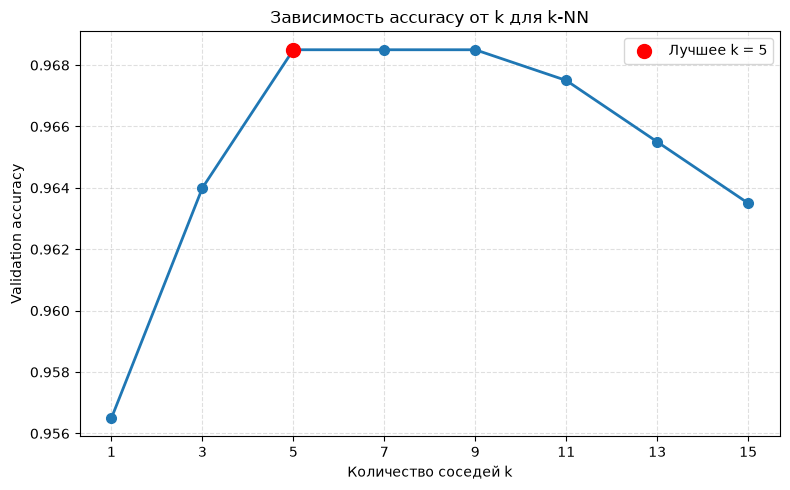

In [7]:
with open(ARTIFACTS / "knn_validation.json", "r", encoding="utf-8") as f:
    results = json.load(f)

knn_val = {int(k): v for k, v in results["knn_val"].items()}
ks = sorted(knn_val)
accuracies = [knn_val[k] for k in ks]
best_k = int(results["best_k"])

plt.figure(figsize=(8, 5))
plt.plot(ks, accuracies, marker="o", linewidth=2, markersize=7)
plt.scatter(
    [best_k], [knn_val[best_k]],
    color="red", s=100, zorder=3, label=f"Лучшее k = {best_k}"
)
plt.xticks(ks)
plt.xlabel("Количество соседей k")
plt.ylabel("Validation accuracy")
plt.title("Зависимость accuracy от k для k-NN")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

### Линейная проверка и test

*Вес: 1 балл.*

**Постановка.** Frozen-признаки оценивают независимыми простыми классификаторами.

Выполните следующие действия:
1. Обучите k-NN и logistic regression только на train.
2. Вычислите test accuracy и macro-F1 после выбора k.

**Результат.** probes.json с измеренными test-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
# Загружаем frozen DINO-признаки
data = np.load(ARTIFACTS / "embeddings.npz")

X_train = data["X_train"]
y_train = data["y_train"]
X_test = data["X_test"]
y_test = data["y_test"]

# Загружаем k, выбранное на validation
with open(ARTIFACTS / "knn_validation.json", "r", encoding="utf-8") as f:
    knn_results = json.load(f)

best_k = int(knn_results["best_k"])

# 1. k-NN: обучаем только на train
knn = KNeighborsClassifier(
    n_neighbors=best_k,
    metric="cosine",
    weights="uniform",
    n_jobs=-1
)
knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

# 2. Logistic regression: обучаем только на train
linear_probe = LogisticRegression(
    max_iter=500,
    random_state=SEED
)
linear_probe.fit(X_train, y_train)

linear_pred = linear_probe.predict(X_test)

# Итоговые test-метрики
probes = {
    "knn": {
        "best_k": best_k,
        "accuracy": float(accuracy_score(y_test, knn_pred)),
        "macro_f1": float(
            f1_score(y_test, knn_pred, average="macro", zero_division=0)
        )
    },
    "logistic_regression": {
        "accuracy": float(accuracy_score(y_test, linear_pred)),
        "macro_f1": float(
            f1_score(y_test, linear_pred, average="macro", zero_division=0)
        )
    },
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test))
}

with open(ARTIFACTS / "probes.json", "w", encoding="utf-8") as f:
    json.dump(probes, f, ensure_ascii=False, indent=2)

print(json.dumps(probes, ensure_ascii=False, indent=2))
print(f"\nМетрики сохранены: {ARTIFACTS / 'probes.json'}")


{
  "knn": {
    "best_k": 5,
    "accuracy": 0.9632,
    "macro_f1": 0.9631844513475329
  },
  "logistic_regression": {
    "accuracy": 0.968,
    "macro_f1": 0.967998429896495
  },
  "n_train": 10000,
  "n_test": 5000
}

Метрики сохранены: artifacts\probes.json


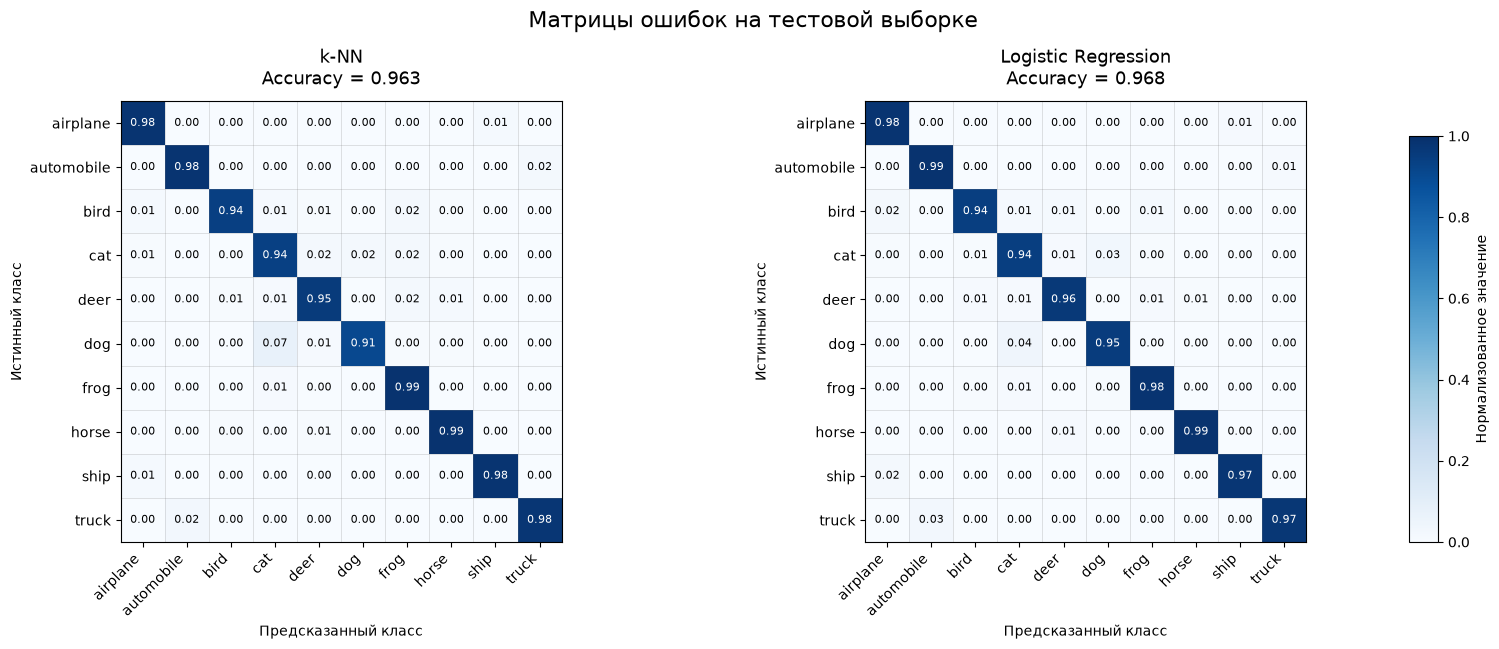

In [9]:
data = np.load(ARTIFACTS / "embeddings.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

with open(ARTIFACTS / "knn_validation.json", "r", encoding="utf-8") as f:
    best_k = int(json.load(f)["best_k"])

knn = KNeighborsClassifier(
    n_neighbors=best_k, metric="cosine",
    weights="uniform", n_jobs=-1
)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

linear_probe = LogisticRegression(max_iter=500, random_state=SEED)
linear_probe.fit(X_train, y_train)
linear_pred = linear_probe.predict(X_test)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
class_ids = np.arange(10)

cm_knn = confusion_matrix(
    y_test, knn_pred, labels=class_ids, normalize="true"
)
cm_linear = confusion_matrix(
    y_test, linear_pred, labels=class_ids, normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for cm, title, pred, ax in [
    (cm_knn, "k-NN", knn_pred, axes[0]),
    (cm_linear, "Logistic Regression", linear_pred, axes[1])
]:
    im = ax.imshow(
        cm, interpolation="nearest",
        cmap="Blues", vmin=0, vmax=1
    )

    ax.set_title(
        f"{title}\nAccuracy = {accuracy_score(y_test, pred):.3f}",
        fontsize=13, pad=12
    )
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
    ax.set_xticks(class_ids)
    ax.set_yticks(class_ids)
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticklabels(class_names)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, f"{cm[i, j]:.2f}",
                ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black",
                fontsize=8
            )

    ax.set_xticks(np.arange(-0.5, 10, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)
    ax.grid(
        which="minor", color="gray",
        linestyle="-", linewidth=0.4, alpha=0.4
    )
    ax.tick_params(which="minor", bottom=False, left=False)

# Отдельная шкала справа от обеих матриц
fig.subplots_adjust(
    left=0.07, right=0.88, bottom=0.22,
    top=0.85, wspace=0.35
)
cbar_ax = fig.add_axes([0.91, 0.22, 0.018, 0.58])
fig.colorbar(im, cax=cbar_ax, label="Нормализованное значение")

fig.suptitle("Матрицы ошибок на тестовой выборке", fontsize=16)
plt.show()

### Кривая объёма разметки

*Вес: 1 балл.*

**Постановка.** Малые размеченные подмножества выявляют sample efficiency представления.

Выполните следующие действия:
1. Создайте сбалансированные подмножества train по фиксированному seed.
2. Обучите отдельный linear probe для каждой доли и сохраните результаты.

**Результат.** label_curve.json с числом объектов и измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
data = np.load(ARTIFACTS / "embeddings.npz")
X_train = data["X_train"]
y_train = data["y_train"]
X_val = data["X_val"]
y_val = data["y_val"]

fractions = [0.01, 0.10, 1.00]
classes = np.unique(y_train)
rng = np.random.RandomState(SEED)

# Один раз перемешиваем индексы каждого класса,
# чтобы подмножества разных размеров были вложенными.
class_indices = {
    cls: rng.permutation(np.flatnonzero(y_train == cls))
    for cls in classes
}

results = []

for fraction in fractions:
    # Число примеров каждого класса.
    # В FAST_DEV_RUN минимум один пример на класс.
    if fraction == 1.0:
        n_per_class = min(len(class_indices[cls]) for cls in classes)
    else:
        n_per_class = max(
            1, int(round(fraction * len(X_train) / len(classes)))
        )

    selected_indices = np.concatenate([
        class_indices[cls][:n_per_class]
        for cls in classes
    ])

    X_subset = X_train[selected_indices]
    y_subset = y_train[selected_indices]

    linear_probe = LogisticRegression(
        max_iter=500,
        random_state=SEED
    )
    linear_probe.fit(X_subset, y_subset)

    val_pred = linear_probe.predict(X_val)
    accuracy = accuracy_score(y_val, val_pred)

    results.append({
        "fraction": fraction,
        "n_objects": int(len(selected_indices)),
        "samples_per_class": int(n_per_class),
        "accuracy": float(accuracy)
    })

label_curve = {
    "seed": SEED,
    "metric": "accuracy",
    "evaluation_split": "validation",
    "results": results
}

output_path = ARTIFACTS / "label_curve.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(label_curve, f, ensure_ascii=False, indent=2)

print("Кривая объёма разметки:")
for result in results:
    print(
        f"{result['fraction']:.0%} разметки | "
        f"объектов: {result['n_objects']} | "
        f"на класс: {result['samples_per_class']} | "
        f"validation accuracy: {result['accuracy']:.4f}"
    )

print(f"\nРезультаты сохранены: {output_path}")

Кривая объёма разметки:
1% разметки | объектов: 100 | на класс: 10 | validation accuracy: 0.9100
10% разметки | объектов: 1000 | на класс: 100 | validation accuracy: 0.9565
100% разметки | объектов: 10000 | на класс: 1000 | validation accuracy: 0.9685

Результаты сохранены: artifacts\label_curve.json


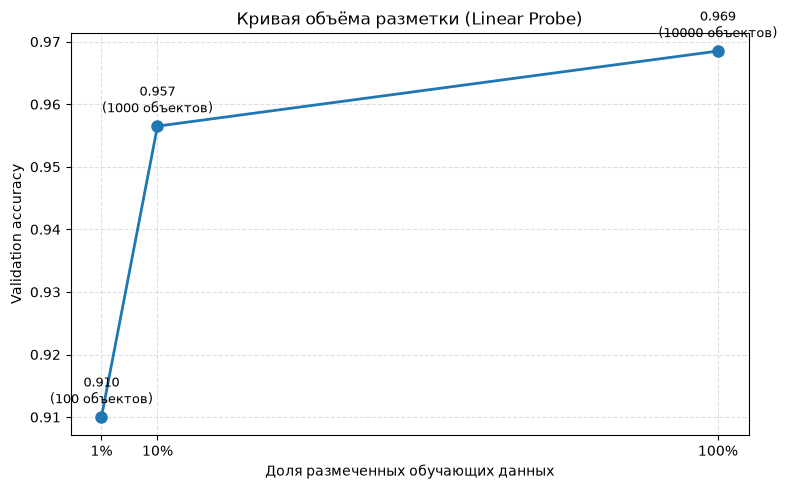

In [11]:
label_curve_path = ARTIFACTS / "label_curve.json"

with open(label_curve_path, "r", encoding="utf-8") as f:
    label_curve = json.load(f)

results = label_curve["results"]

fractions = [r["fraction"] * 100 for r in results]
accuracies = [r["accuracy"] for r in results]
n_objects = [r["n_objects"] for r in results]

plt.figure(figsize=(8, 5))
plt.plot(fractions, accuracies, marker="o", linewidth=2, markersize=8)

for x, y, n in zip(fractions, accuracies, n_objects):
    plt.annotate(
        f"{y:.3f}\n({n} объектов)",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9
    )

plt.xticks(fractions, [f"{x:.0f}%" for x in fractions])
plt.xlabel("Доля размеченных обучающих данных")
plt.ylabel("Validation accuracy")
plt.title("Кривая объёма разметки (Linear Probe)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Контрастивная адаптация encoder

*Вес: 1 балл.*

**Постановка.** Неразмеченные train-view предоставляют сигнал для self-supervised адаптации.

Выполните следующие действия:
1. Создайте две аугментации одних train-изображений.
2. Оптимизируйте InfoNCE и сохраните обновлённый encoder.

**Результат.** encoder_adapted.pt после реальных optimizer steps.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [16]:
# Настройки обучения
ADAPTED_ENCODER_PATH = ARTIFACTS / "encoder_adapted.pt"
BATCH_SIZE = 4 if FAST_DEV_RUN else 16
MAX_STEPS = 2 if FAST_DEV_RUN else 30
TEMPERATURE = 0.1
LEARNING_RATE = 1e-6
MAX_GRAD_NORM = 1.0

# Две независимые аугментации одного изображения
view_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.5, 1.0),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.4,
            contrast=0.4,
            saturation=0.2,
            hue=0.1
        )
    ], p=0.8),
    transforms.RandomGrayscale(p=0.2),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])


class ContrastiveViewsDataset(Dataset):
    def __init__(self, base_dataset, indices, view_transform):
        self.base_dataset = base_dataset
        self.indices = indices
        self.view_transform = view_transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, _ = self.base_dataset[int(self.indices[index])]
        view1 = self.view_transform(image)
        view2 = self.view_transform(image)
        return view1, view2


contrastive_dataset = ContrastiveViewsDataset(
    ds, train_idx, view_transform
)

contrastive_loader = DataLoader(
    contrastive_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0
)

# Загружаем исходный предобученный DINOv2
encoder = torch.hub.load(
    "facebookresearch/dinov2", "dinov2_vits14"
).to(DEVICE)
encoder.train()

optimizer = torch.optim.AdamW(
    encoder.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)


def info_nce_loss(z1, z2, temperature=0.1):
    batch_size = z1.shape[0]

    # Вычисляем сходство в float32 для численной устойчивости
    z1 = F.normalize(z1.float(), dim=1)
    z2 = F.normalize(z2.float(), dim=1)
    z = torch.cat([z1, z2], dim=0)

    logits = (z @ z.T) / temperature
    logits.fill_diagonal_(float("-inf"))

    # Для каждого view положительная пара — соответствующий второй view
    targets = torch.cat([
        torch.arange(batch_size, 2 * batch_size, device=z.device),
        torch.arange(batch_size, device=z.device)
    ])

    return F.cross_entropy(logits, targets)


# Обучение
loss_history = []
step = 0

while step < MAX_STEPS:
    for view1, view2 in contrastive_loader:
        view1 = view1.to(DEVICE)
        view2 = view2.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        z1 = encoder(view1)
        z2 = encoder(view2)

        loss = info_nce_loss(z1, z2, TEMPERATURE)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"InfoNCE loss стал NaN или Inf на шаге {step + 1}. "
                "Обучение остановлено."
            )

        loss.backward()

        grad_norm = torch.nn.utils.clip_grad_norm_(
            encoder.parameters(),
            max_norm=MAX_GRAD_NORM,
            error_if_nonfinite=True
        )

        optimizer.step()

        loss_value = float(loss.detach().cpu())
        loss_history.append(loss_value)
        step += 1

        if step % 10 == 0 or step == 1:
            print(
                f"Step {step}/{MAX_STEPS}, "
                f"InfoNCE loss: {loss_value:.4f}, "
                f"grad norm: {float(grad_norm):.4f}"
            )

        if step >= MAX_STEPS:
            break

# Сохраняем обновлённые веса encoder
torch.save(encoder.state_dict(), ADAPTED_ENCODER_PATH)

# Сохраняем сведения об обучении
adaptation_info = {
    "encoder": "dinov2_vits14",
    "objective": "InfoNCE",
    "steps": step,
    "batch_size": BATCH_SIZE,
    "temperature": TEMPERATURE,
    "learning_rate": LEARNING_RATE,
    "max_grad_norm": MAX_GRAD_NORM,
    "initial_loss": loss_history[0],
    "final_loss": loss_history[-1],
    "device": DEVICE
}

with open(
    ARTIFACTS / "encoder_adaptation.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(adaptation_info, f, ensure_ascii=False, indent=2)

print(f"\nАдаптированный encoder сохранён: {ADAPTED_ENCODER_PATH}")
print(f"Выполнено optimizer steps: {step}")
print(f"Начальный InfoNCE loss: {loss_history[0]:.4f}")
print(f"Последний InfoNCE loss: {loss_history[-1]:.4f}")

Using cache found in C:\Users\anton/.cache\torch\hub\facebookresearch_dinov2_main


Step 1/30, InfoNCE loss: 0.2356, grad norm: 143.0812
Step 10/30, InfoNCE loss: 0.1312, grad norm: 114.7881
Step 20/30, InfoNCE loss: 0.1384, grad norm: 88.0094
Step 30/30, InfoNCE loss: 0.0628, grad norm: 53.7042

Адаптированный encoder сохранён: artifacts\encoder_adapted.pt
Выполнено optimizer steps: 30
Начальный InfoNCE loss: 0.2356
Последний InfoNCE loss: 0.0628


### Признаки после адаптации

*Вес: 1 балл.*

**Постановка.** Сравнение до и после адаптации требует одних и тех же изображений.

Выполните следующие действия:
1. Пересчитайте признаки train/validation/test обновлённым encoder.
2. Обучите новый linear probe на train.

**Результат.** Матрица X_new и обученный new_linear.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [17]:
# Пути для результатов
ADAPTED_ENCODER_PATH = ARTIFACTS / "encoder_adapted.pt"
NEW_EMBEDDINGS_PATH = ARTIFACTS / "X_new.npz"
NEW_LINEAR_PATH = ARTIFACTS / "new_linear.joblib"

EXTRACT_BATCH_SIZE = 4 if FAST_DEV_RUN else 8

# Загружаем обученный на предыдущем этапе encoder
encoder = torch.hub.load(
    "facebookresearch/dinov2", "dinov2_vits14"
).to(DEVICE)

encoder.load_state_dict(
    torch.load(
        ADAPTED_ENCODER_PATH,
        map_location=DEVICE,
        weights_only=True
    )
)
encoder.eval()

# Используем те же разбиения, что и до адаптации
train_idx = np.asarray(train_idx, dtype=np.int64)
val_idx = np.asarray(val_idx, dtype=np.int64)
test_idx = np.asarray(test_idx, dtype=np.int64)

train_extract_loader = DataLoader(
    Subset(ds, train_idx.tolist()),
    batch_size=EXTRACT_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)
val_extract_loader = DataLoader(
    Subset(ds, val_idx.tolist()),
    batch_size=EXTRACT_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)
test_extract_loader = DataLoader(
    Subset(test_ds, test_idx.tolist()),
    batch_size=EXTRACT_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Та же предобработка, что использовалась для исходных embeddings
mean = torch.tensor(
    [0.485, 0.456, 0.406], device=DEVICE
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225], device=DEVICE
).view(1, 3, 1, 1)


def extract_new_embeddings(data_loader):
    features = []

    with torch.inference_mode():
        for images, _ in data_loader:
            images = images.to(DEVICE)

            images = F.interpolate(
                images,
                size=(256, 256),
                mode="bicubic",
                align_corners=False,
                antialias=True
            )
            images = images[:, :, 16:240, 16:240]
            images = (images - mean) / std

            embeddings = encoder(images)
            embeddings = F.normalize(
                embeddings.float(), p=2, dim=1
            )

            features.append(embeddings.cpu().numpy())

    return np.concatenate(features, axis=0).astype(np.float32)


# Пересчитываем признаки для всех трёх разбиений
X_train_new = extract_new_embeddings(train_extract_loader)
X_val_new = extract_new_embeddings(val_extract_loader)
X_test_new = extract_new_embeddings(test_extract_loader)

# Метки соответствуют тем же индексам изображений
y_train_new = np.asarray(ds.targets)[train_idx]
y_val_new = np.asarray(ds.targets)[val_idx]
y_test_new = np.asarray(test_ds.targets)[test_idx]

# Единая матрица признаков: train, validation, test
X_new = np.concatenate(
    [X_train_new, X_val_new, X_test_new],
    axis=0
)

# Сохраняем общую матрицу и её разбиения
np.savez_compressed(
    NEW_EMBEDDINGS_PATH,
    X_new=X_new,
    X_train_new=X_train_new,
    X_val_new=X_val_new,
    X_test_new=X_test_new,
    y_train=y_train_new,
    y_val=y_val_new,
    y_test=y_test_new,
    train_indices=train_idx,
    val_indices=val_idx,
    test_indices=test_idx
)

# Обучаем новый linear probe только на train
new_linear = LogisticRegression(
    max_iter=500,
    random_state=SEED
)
new_linear.fit(X_train_new, y_train_new)

# Сохраняем обученный классификатор
joblib.dump(new_linear, NEW_LINEAR_PATH)

# Оцениваем модель без подбора параметров по test
val_pred = new_linear.predict(X_val_new)
test_pred = new_linear.predict(X_test_new)

results = {
    "n_train": int(len(X_train_new)),
    "n_val": int(len(X_val_new)),
    "n_test": int(len(X_test_new)),
    "embedding_dim": int(X_new.shape[1]),
    "validation_accuracy": float(
        accuracy_score(y_val_new, val_pred)
    ),
    "validation_macro_f1": float(
        f1_score(y_val_new, val_pred, average="macro", zero_division=0)
    ),
    "test_accuracy": float(
        accuracy_score(y_test_new, test_pred)
    ),
    "test_macro_f1": float(
        f1_score(y_test_new, test_pred, average="macro", zero_division=0)
    )
}

with open(
    ARTIFACTS / "adapted_probe_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print("Признаки после адаптации:")
print("Train:", X_train_new.shape)
print("Validation:", X_val_new.shape)
print("Test:", X_test_new.shape)
print("Общая матрица X_new:", X_new.shape)

print("\nРезультаты нового linear probe:")
print(json.dumps(results, ensure_ascii=False, indent=2))

print(f"\nМатрица признаков сохранена: {NEW_EMBEDDINGS_PATH}")
print(f"Linear probe сохранён: {NEW_LINEAR_PATH}")

Using cache found in C:\Users\anton/.cache\torch\hub\facebookresearch_dinov2_main


Признаки после адаптации:
Train: (10000, 384)
Validation: (2000, 384)
Test: (5000, 384)
Общая матрица X_new: (17000, 384)

Результаты нового linear probe:
{
  "n_train": 10000,
  "n_val": 2000,
  "n_test": 5000,
  "embedding_dim": 384,
  "validation_accuracy": 0.9725,
  "validation_macro_f1": 0.9724581075903055,
  "test_accuracy": 0.9742,
  "test_macro_f1": 0.9742097282005859
}

Матрица признаков сохранена: artifacts\X_new.npz
Linear probe сохранён: artifacts\new_linear.joblib


### Точность адаптированного probe

*Вес: 1 балл.*

**Постановка.** Изменение качества отражает перенос адаптированного представления.

Выполните следующие действия:
1. Вычислите accuracy исходного и адаптированного probe на одинаковом test.
2. Сохраните парный результат.

**Результат.** adaptation.json с наблюдаемыми показателями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [18]:
# Исходные признаки
original_data = np.load(ARTIFACTS / "embeddings.npz")
X_train = original_data["X_train"]
y_train = original_data["y_train"]
X_test = original_data["X_test"]
y_test = original_data["y_test"]

# Признаки после адаптации
adapted_data = np.load(ARTIFACTS / "X_new.npz")
X_test_new = adapted_data["X_test_new"]
y_test_new = adapted_data["y_test"]

# Проверяем, что обе модели оцениваются на одинаковых объектах
assert np.array_equal(y_test, y_test_new)
assert np.array_equal(
    original_data["test_indices"],
    adapted_data["test_indices"]
)

# Обучаем исходный linear probe на исходных train-признаках
original_linear = LogisticRegression(
    max_iter=500,
    random_state=SEED
)
original_linear.fit(X_train, y_train)

# Загружаем linear probe, обученный на адаптированных признаках
new_linear = joblib.load(ARTIFACTS / "new_linear.joblib")

# Предсказания на одном и том же test
original_pred = original_linear.predict(X_test)
adapted_pred = new_linear.predict(X_test_new)

# Метрики
original_accuracy = accuracy_score(y_test, original_pred)
adapted_accuracy = accuracy_score(y_test_new, adapted_pred)

original_macro_f1 = f1_score(
    y_test, original_pred, average="macro", zero_division=0
)
adapted_macro_f1 = f1_score(
    y_test_new, adapted_pred, average="macro", zero_division=0
)

accuracy_difference = adapted_accuracy - original_accuracy

adaptation_results = {
    "n_test": int(len(y_test)),
    "original_probe": {
        "accuracy": float(original_accuracy),
        "macro_f1": float(original_macro_f1)
    },
    "adapted_probe": {
        "accuracy": float(adapted_accuracy),
        "macro_f1": float(adapted_macro_f1)
    },
    "accuracy_difference": float(accuracy_difference),
    "accuracy_difference_percentage_points": float(
        accuracy_difference * 100
    )
}

# Сохраняем парное сравнение
output_path = ARTIFACTS / "adaptation.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(adaptation_results, f, ensure_ascii=False, indent=2)

print("Сравнение на одной тестовой выборке:")
print(f"Исходный probe accuracy:      {original_accuracy:.4f}")
print(f"Адаптированный probe accuracy: {adapted_accuracy:.4f}")
print(
    f"Разница accuracy:              "
    f"{accuracy_difference * 100:+.2f} п.п."
)
print(f"Исходный probe macro-F1:       {original_macro_f1:.4f}")
print(f"Адаптированный probe macro-F1: {adapted_macro_f1:.4f}")
print(f"\nРезультаты сохранены: {output_path}")

Сравнение на одной тестовой выборке:
Исходный probe accuracy:      0.9680
Адаптированный probe accuracy: 0.9742
Разница accuracy:              +0.62 п.п.
Исходный probe macro-F1:       0.9680
Адаптированный probe macro-F1: 0.9742

Результаты сохранены: artifacts\adaptation.json


### Визуальные соседи

*Вес: 1 балл.*

**Постановка.** Ранжирование соседей позволяет выявить смешение категорий.

Выполните следующие действия:
1. Найдите ближайшие train-объекты для фиксированных test-запросов.
2. Сохраните расстояния, индексы и метки.

**Результат.** neighbors.json с фактическими близкими изображениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [19]:
# Загружаем исходные DINOv2-признаки
data = np.load(ARTIFACTS / "embeddings.npz")

X_train = data["X_train"]
y_train = data["y_train"]
X_test = data["X_test"]
y_test = data["y_test"]

train_indices = data["train_indices"]
test_indices = data["test_indices"]

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Число фиксированных test-запросов и соседей
n_queries = min(5, len(X_test))
top_k = min(5, len(X_train))

# Индексы запросов фиксированы и воспроизводимы
query_positions = np.arange(n_queries)

# Ищем ближайшие train-объекты по косинусному расстоянию
neighbor_model = NearestNeighbors(
    n_neighbors=top_k,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)
neighbor_model.fit(X_train)

distances, neighbor_positions = neighbor_model.kneighbors(
    X_test[query_positions]
)

neighbors_results = {
    "metric": "cosine",
    "feature_space": "original_dinov2",
    "n_queries": int(n_queries),
    "top_k": int(top_k),
    "queries": []
}

for i, query_position in enumerate(query_positions):
    query_label = int(y_test[query_position])

    query_result = {
        "query_position": int(query_position),
        "test_index": int(test_indices[query_position]),
        "label": query_label,
        "class_name": class_names[query_label],
        "neighbors": []
    }

    for rank, (distance, neighbor_position) in enumerate(
        zip(distances[i], neighbor_positions[i]), start=1
    ):
        neighbor_position = int(neighbor_position)
        neighbor_label = int(y_train[neighbor_position])

        query_result["neighbors"].append({
            "rank": int(rank),
            "train_position": neighbor_position,
            "train_index": int(train_indices[neighbor_position]),
            "label": neighbor_label,
            "class_name": class_names[neighbor_label],
            "cosine_distance": float(distance)
        })

    neighbors_results["queries"].append(query_result)

output_path = ARTIFACTS / "neighbors.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(neighbors_results, f, ensure_ascii=False, indent=2)

# Краткий вывод для проверки
for query in neighbors_results["queries"]:
    print(
        f"\nTest index {query['test_index']} "
        f"— {query['class_name']}"
    )
    for neighbor in query["neighbors"]:
        print(
            f"  #{neighbor['rank']}: "
            f"train index {neighbor['train_index']}, "
            f"class={neighbor['class_name']}, "
            f"distance={neighbor['cosine_distance']:.4f}"
        )

print(f"\nРезультаты сохранены: {output_path}")


Test index 6613 — ship
  #1: train index 6067, class=airplane, distance=0.3555
  #2: train index 44685, class=ship, distance=0.3792
  #3: train index 27630, class=deer, distance=0.4191
  #4: train index 20136, class=deer, distance=0.4505
  #5: train index 19882, class=deer, distance=0.4520

Test index 9907 — automobile
  #1: train index 8563, class=automobile, distance=0.3101
  #2: train index 39322, class=automobile, distance=0.3487
  #3: train index 4609, class=automobile, distance=0.3701
  #4: train index 20557, class=automobile, distance=0.3819
  #5: train index 45210, class=automobile, distance=0.3863

Test index 6721 — horse
  #1: train index 23649, class=horse, distance=0.4072
  #2: train index 40817, class=horse, distance=0.4350
  #3: train index 17472, class=horse, distance=0.4410
  #4: train index 49175, class=horse, distance=0.4484
  #5: train index 35924, class=horse, distance=0.4510

Test index 8901 — dog
  #1: train index 7726, class=dog, distance=0.2721
  #2: train inde

### Чистота ближайшего окружения

*Вес: 1 балл.*

**Постановка.** Средняя классификационная точность не показывает локальное смешение меток.

Выполните следующие действия:
1. По уже вычисленным пяти соседям найдите долю совпадений классов.
2. Выведите среднюю чистоту и примеры с минимальной чистотой.

**Результат.** neighborhood_purity.json с измерениями на test-запросах.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [20]:
NEIGHBORS_PATH = ARTIFACTS / "neighbors.json"
PURITY_PATH = ARTIFACTS / "neighborhood_purity.json"

with open(NEIGHBORS_PATH, "r", encoding="utf-8") as f:
    neighbors_data = json.load(f)

query_results = []

for query in neighbors_data["queries"]:
    query_label = query["label"]
    neighbors = query["neighbors"]

    matching = sum(
        neighbor["label"] == query_label
        for neighbor in neighbors
    )
    purity = matching / len(neighbors)

    query_results.append({
        "query_position": query["query_position"],
        "test_index": query["test_index"],
        "label": query_label,
        "class_name": query["class_name"],
        "n_neighbors": len(neighbors),
        "matching_neighbors": int(matching),
        "purity": float(purity),
        "neighbor_classes": [
            neighbor["class_name"] for neighbor in neighbors
        ]
    })

mean_purity = float(np.mean([
    query["purity"] for query in query_results
]))

min_purity = min(query["purity"] for query in query_results)
least_pure_queries = [
    query for query in query_results
    if query["purity"] == min_purity
]

purity_results = {
    "metric": "neighborhood_purity",
    "neighbor_source": "neighbors.json",
    "top_k": neighbors_data["top_k"],
    "n_queries": len(query_results),
    "mean_purity": mean_purity,
    "minimum_purity": float(min_purity),
    "least_pure_queries": least_pure_queries,
    "queries": query_results
}

with open(PURITY_PATH, "w", encoding="utf-8") as f:
    json.dump(purity_results, f, ensure_ascii=False, indent=2)

print(f"Средняя чистота окружения: {mean_purity:.3f}")
print(f"Минимальная чистота: {min_purity:.3f}")

print("\nПримеры с минимальной чистотой:")
for query in least_pure_queries:
    print(
        f"Test index {query['test_index']} "
        f"({query['class_name']}): "
        f"{query['matching_neighbors']}/{query['n_neighbors']} "
        f"совпадений, purity={query['purity']:.2f}"
    )
    print("  Классы соседей:", ", ".join(query["neighbor_classes"]))

print(f"\nРезультаты сохранены: {PURITY_PATH}")

Средняя чистота окружения: 0.640
Минимальная чистота: 0.200

Примеры с минимальной чистотой:
Test index 6613 (ship): 1/5 совпадений, purity=0.20
  Классы соседей: airplane, ship, deer, deer, deer
Test index 6756 (dog): 1/5 совпадений, purity=0.20
  Классы соседей: dog, cat, cat, cat, cat

Результаты сохранены: artifacts\neighborhood_purity.json


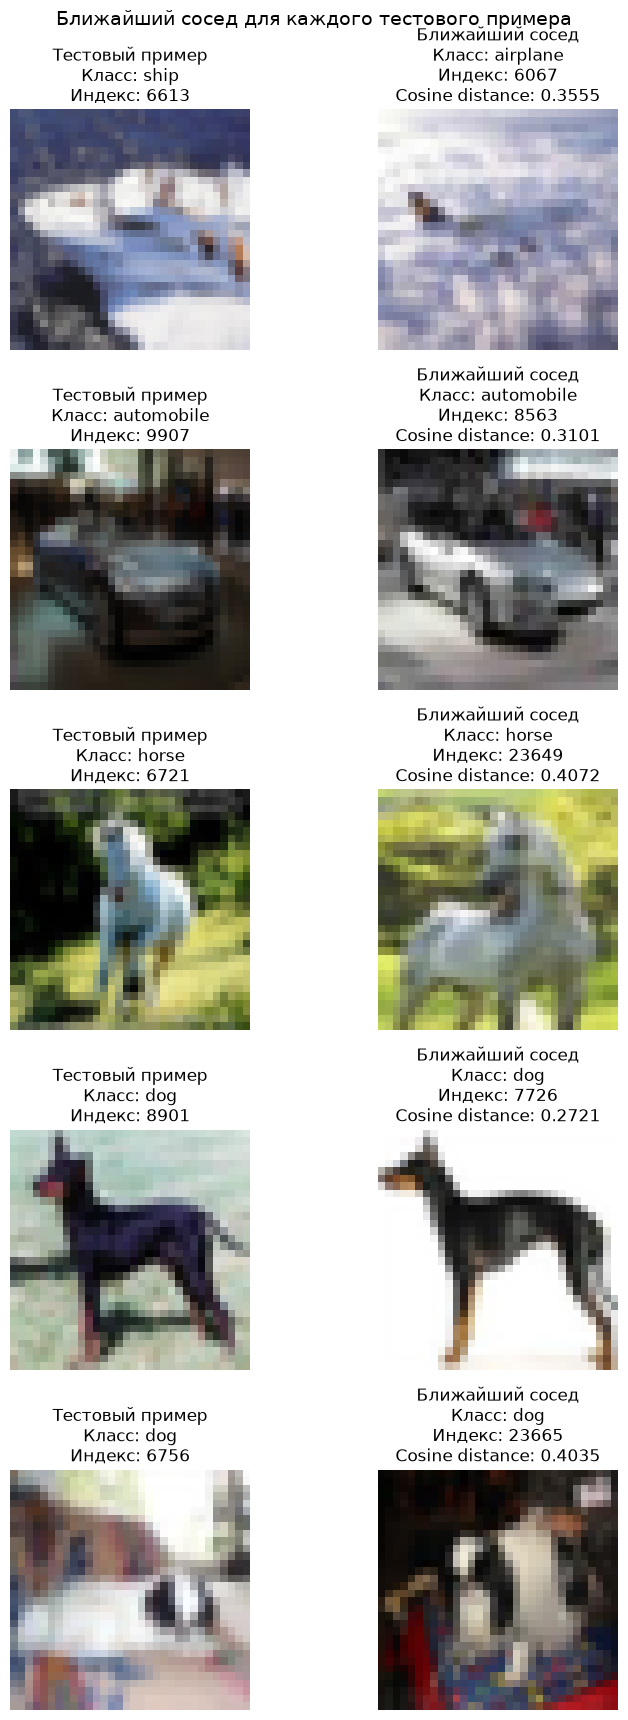

In [21]:
NEIGHBORS_PATH = ARTIFACTS / "neighbors.json"

with open(NEIGHBORS_PATH, "r", encoding="utf-8") as f:
    neighbors_data = json.load(f)

# Загружаем CIFAR-10 без преобразований, чтобы показывать исходные изображения.
test_images = datasets.CIFAR10(
    root=str(DATA_ROOT),
    train=False,
    download=True
)

train_images = datasets.CIFAR10(
    root=str(DATA_ROOT),
    train=True,
    download=True
)

# Названия классов CIFAR-10
class_names = train_images.classes

queries = neighbors_data["queries"]
n_queries = len(queries)

fig, axes = plt.subplots(
    n_queries, 2,
    figsize=(8, 3.5 * n_queries),
    squeeze=False
)

for row, query in enumerate(queries):
    test_index = query["test_index"]
    test_label = query["label"]

    # Берём первого соседа — он имеет минимальное расстояние.
    nearest = min(
        query["neighbors"],
        key=lambda neighbor: neighbor["rank"]
    )

    train_index = nearest["train_index"]
    neighbor_label = nearest["label"]
    distance = nearest["cosine_distance"]

    test_image, _ = test_images[test_index]
    neighbor_image, _ = train_images[train_index]

    axes[row, 0].imshow(test_image)
    axes[row, 0].set_title(
        f"Тестовый пример\n"
        f"Класс: {class_names[test_label]}\n"
        f"Индекс: {test_index}"
    )
    axes[row, 0].axis("off")

    axes[row, 1].imshow(neighbor_image)
    axes[row, 1].set_title(
        f"Ближайший сосед\n"
        f"Класс: {class_names[neighbor_label]}\n"
        f"Индекс: {train_index}\n"
        f"Cosine distance: {distance:.4f}"
    )
    axes[row, 1].axis("off")

fig.suptitle(
    "Ближайший сосед для каждого тестового примера",
    fontsize=14
)
plt.tight_layout()
plt.show()

### Творческий бонус: ошибки соседства

*Вес: 1 дополнительный балл.*

**Постановка.** Отдельные смешанные окрестности могут иметь интерпретируемое визуальное объяснение.

Выполните следующие действия:
1. Выберите два test-изображения с низкой чистотой соседей.
2. Сохраните коллаж запросов и соответствующих train-соседей.

**Результат.** bonus_neighbors.png и индексы изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


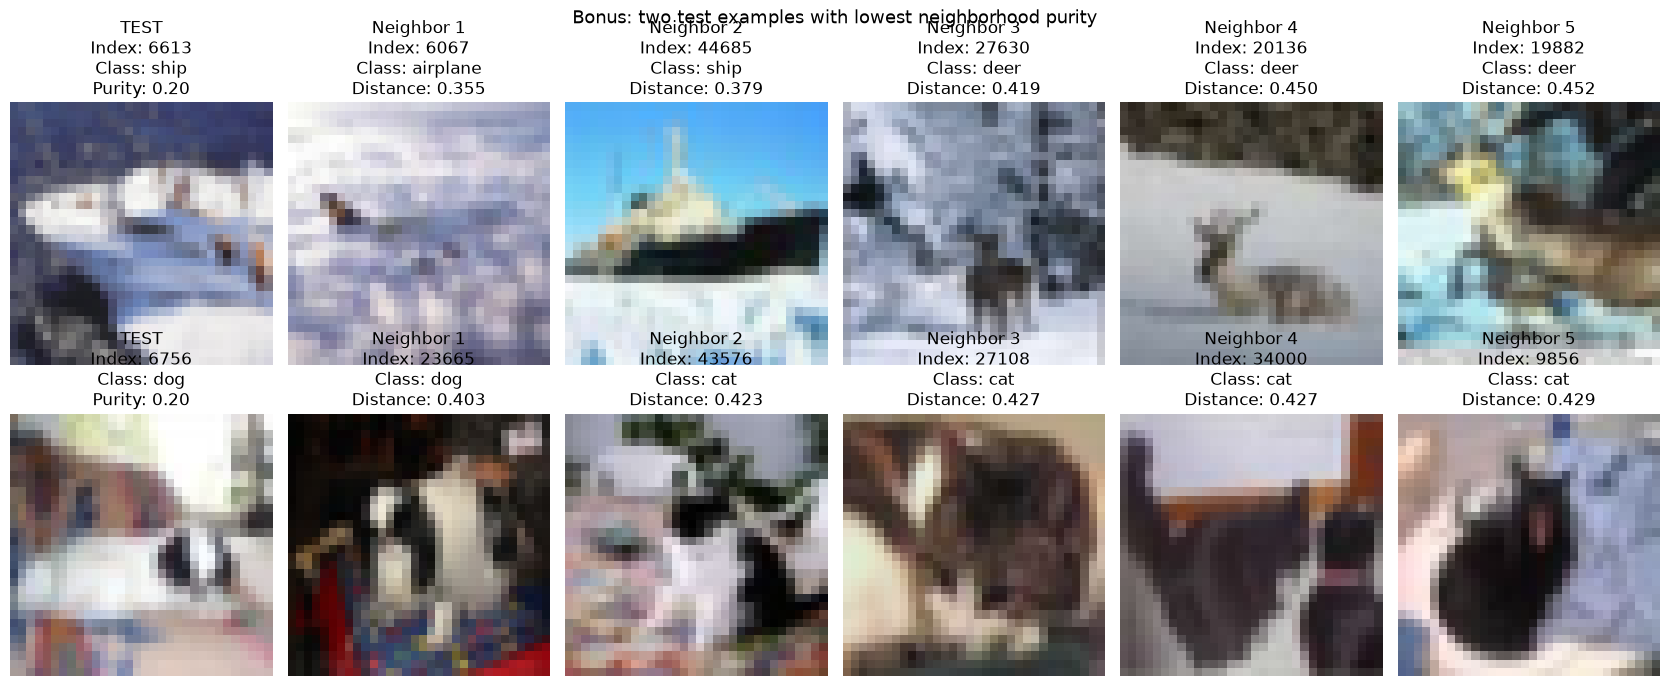

Коллаж сохранён: artifacts\bonus_neighbors.png
Индексы сохранены: artifacts\bonus_neighbors.json

Test index: 6613, class: ship, purity: 0.20
Train indices: [6067, 44685, 27630, 20136, 19882]

Test index: 6756, class: dog, purity: 0.20
Train indices: [23665, 43576, 27108, 34000, 9856]


In [22]:
PURITY_PATH = ARTIFACTS / "neighborhood_purity.json"
NEIGHBORS_PATH = ARTIFACTS / "neighbors.json"
BONUS_IMAGE_PATH = ARTIFACTS / "bonus_neighbors.png"
BONUS_INDICES_PATH = ARTIFACTS / "bonus_neighbors.json"

with open(PURITY_PATH, "r", encoding="utf-8") as f:
    purity_data = json.load(f)

with open(NEIGHBORS_PATH, "r", encoding="utf-8") as f:
    neighbors_data = json.load(f)

# Выбираем два запроса с минимальной чистотой.
selected_purity = sorted(
    purity_data["queries"],
    key=lambda q: q["purity"]
)[:2]

# Индекс тестового изображения -> данные о его соседях.
neighbors_by_index = {
    q["test_index"]: q
    for q in neighbors_data["queries"]
}

# Объединяем данные из двух JSON по test_index.
selected = []
for purity_query in selected_purity:
    test_index = purity_query["test_index"]
    if test_index in neighbors_by_index:
        query = neighbors_by_index[test_index].copy()
        query["purity"] = purity_query["purity"]
        query["matching_neighbors"] = purity_query["matching_neighbors"]
        query["n_neighbors"] = purity_query["n_neighbors"]
        selected.append(query)

train_images = datasets.CIFAR10(
    root=str(DATA_ROOT), train=True, download=True
)
test_images = datasets.CIFAR10(
    root=str(DATA_ROOT), train=False, download=True
)

class_names = train_images.classes
n_rows = len(selected)
n_neighbors = max(len(q["neighbors"]) for q in selected)

fig, axes = plt.subplots(
    n_rows,
    n_neighbors + 1,
    figsize=(2.8 * (n_neighbors + 1), 3.5 * n_rows),
    squeeze=False
)

saved_queries = []

for row, query in enumerate(selected):
    test_index = query["test_index"]
    test_label = query["label"]

    test_image, _ = test_images[test_index]
    axes[row, 0].imshow(test_image)
    axes[row, 0].set_title(
        f"TEST\nIndex: {test_index}\n"
        f"Class: {class_names[test_label]}\n"
        f"Purity: {query['purity']:.2f}"
    )
    axes[row, 0].axis("off")

    saved_neighbors = []

    for col, neighbor in enumerate(query["neighbors"], start=1):
        train_index = neighbor["train_index"]
        train_label = neighbor["label"]
        train_image, _ = train_images[train_index]

        axes[row, col].imshow(train_image)
        axes[row, col].set_title(
            f"Neighbor {neighbor['rank']}\n"
            f"Index: {train_index}\n"
            f"Class: {class_names[train_label]}\n"
            f"Distance: {neighbor['cosine_distance']:.3f}"
        )
        axes[row, col].axis("off")

        saved_neighbors.append({
            "rank": neighbor["rank"],
            "train_index": train_index,
            "label": train_label,
            "class_name": class_names[train_label],
            "cosine_distance": neighbor["cosine_distance"]
        })

    for col in range(len(query["neighbors"]) + 1, n_neighbors + 1):
        axes[row, col].axis("off")

    saved_queries.append({
        "test_index": test_index,
        "label": test_label,
        "class_name": class_names[test_label],
        "purity": query["purity"],
        "matching_neighbors": query["matching_neighbors"],
        "n_neighbors": query["n_neighbors"],
        "neighbors": saved_neighbors
    })

fig.suptitle(
    "Bonus: two test examples with lowest neighborhood purity",
    fontsize=13
)
plt.tight_layout()
fig.savefig(BONUS_IMAGE_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

bonus_results = {
    "feature_space": neighbors_data["feature_space"],
    "metric": neighbors_data["metric"],
    "selection_criterion": "two lowest neighborhood purity values",
    "queries": saved_queries
}

with open(BONUS_INDICES_PATH, "w", encoding="utf-8") as f:
    json.dump(bonus_results, f, ensure_ascii=False, indent=2)

print(f"Коллаж сохранён: {BONUS_IMAGE_PATH}")
print(f"Индексы сохранены: {BONUS_INDICES_PATH}")

for query in saved_queries:
    print(
        f"\nTest index: {query['test_index']}, "
        f"class: {query['class_name']}, "
        f"purity: {query['purity']:.2f}"
    )
    print(
        "Train indices:",
        [n["train_index"] for n in query["neighbors"]]
    )

## Анализ результатов

На отложенной тестовой выборке я сравнил исходные представления DINOv2 и представления после адаптации. Качество оценивалось с помощью kNN и логистической регрессии. Точность исходной модели составила 0.963/0.968, после адаптации — 0.974. Это показывает, что адаптация незначительно качество классификации.

При проверке ближайших соседей средняя чистота окрестности составила 0.64. Среди соседей встречались изображения других классов, что может быть связано с визуальным сходством объектов разных категорий. Чаще всего модель путала изображения с похожим фоном (самолет в облаках, олени на снегу, корабль во льдах) или похожие объекты (кошки и собаки).

Бюджет эксперимента составил 10000 обучающих примеров и 30 шагов адаптации. Основные ограничения — небольшой объём данных, ограниченное число шагов и возможная нестабильность обучения.